# Xe Adsorption in Ag-Modified Chabazite

**Goal:** use DFT and MatterSim data to understand Xe adsorption in Ag-modified chabazite and prepare a regression workflow for screening promising adsorption configurations.

### Simple answers to the assignment
1. **What does the data look like?** Raw VASP files, current pore data, MatterSim outputs
2. **What algorithms are suitable?** Dummy baseline, Linear Regression, Random Forest, Gradient Boosting.
3. **What is success?** MAE, RMSE, \(R^2\), correct ranking of strong/weak adsorption.
4. **What still needs help?** MLIP(machine-learning interatomic potential) choice, DFT validation, descriptor design, dataset size, leakage control, competing species.

# 1. Research Question

### Main question
How do pore geometry and Ag environment affect Xe adsorption in chabazite?

### Current target
\(E_{ads}\)

This is a **regression problem** because adsorption energy is continuous.

### Candidate descriptors
- ring type: 6MR / 8MR
- Ag charge state
- Ag site / Ag near vs far from Xe
- Xe–Ag distance
- pore geometry
- Ag nanoparticle size / concentration

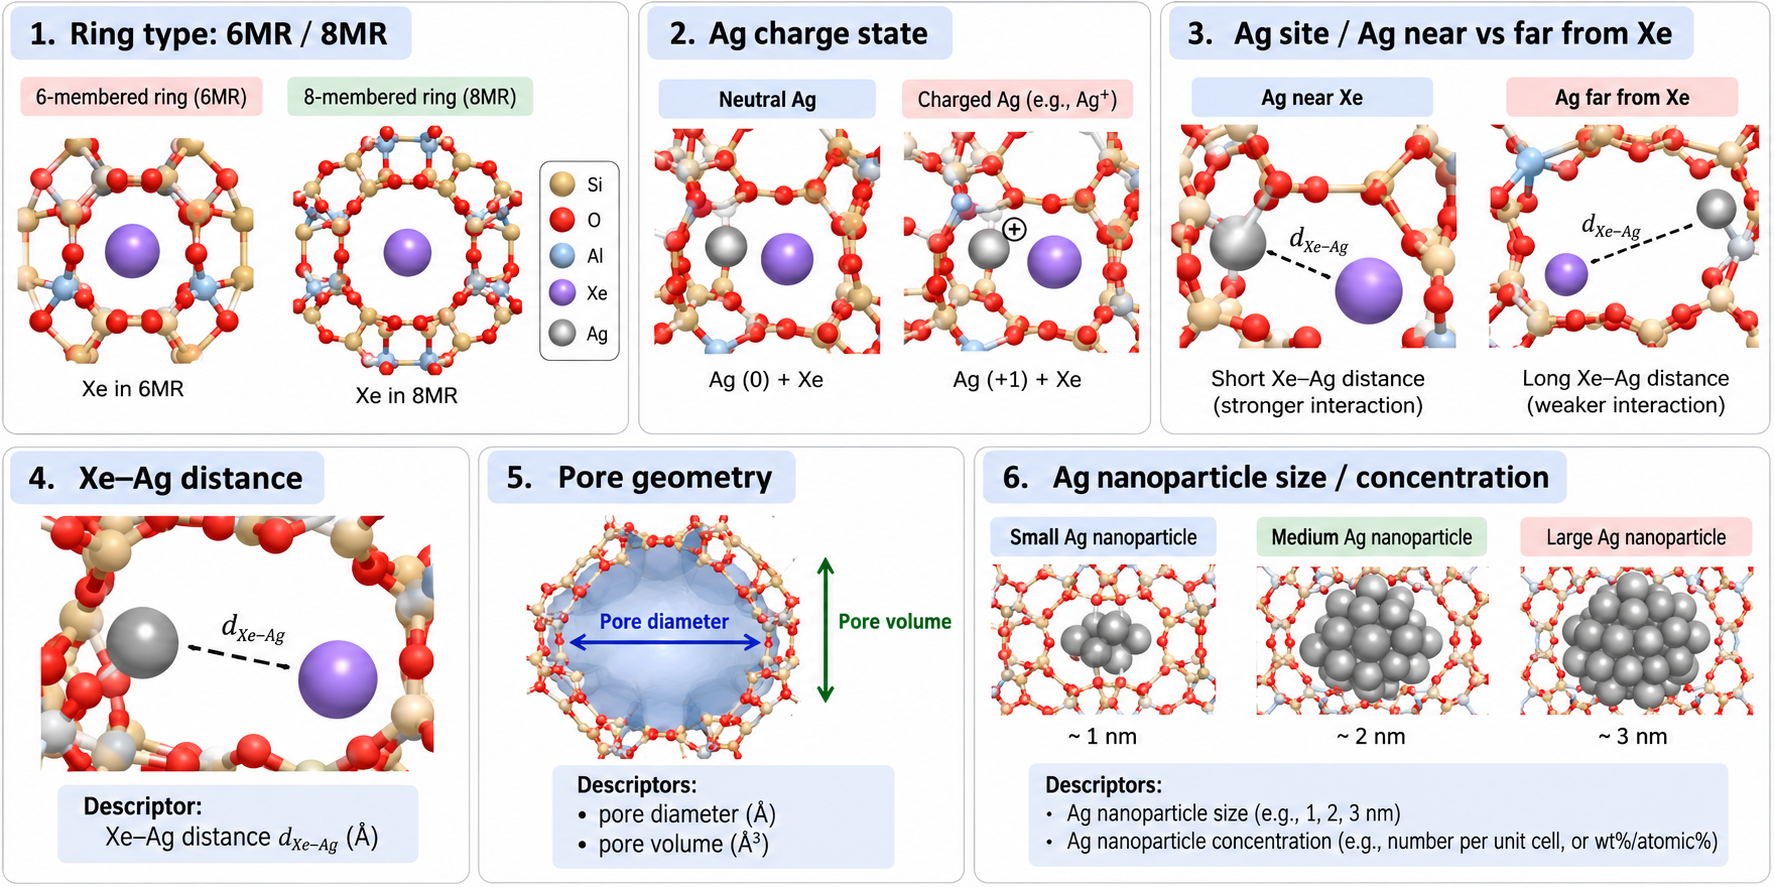

In [1]:
from IPython.display import Image, display

display(Image(filename="1.png"))

# 2. Real MatterSim Demonstration

In [10]:
import warnings
warnings.filterwarnings("ignore")

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from pathlib import Path
from ase.io import read, write
from ase.optimize import BFGS
from ase.visualize.plot import plot_atoms
from mattersim.forcefield import MatterSimCalculator

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cpu


Formula: C3B12
Number of atoms: 15


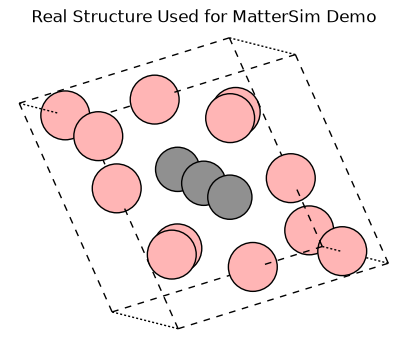

In [3]:
STRUCTURE_PATH = Path("Ground_state_energy/B4C/CONTCAR")

atoms = read(STRUCTURE_PATH)

print("Formula:", atoms.get_chemical_formula())
print("Number of atoms:", len(atoms))

fig, ax = plt.subplots(figsize=(5,5))
plot_atoms(atoms, ax, radii=0.55, rotation=("15x,20y,10z"))
ax.set_title("Real Structure Used for MatterSim Demo")
ax.set_axis_off()
plt.show()

In [4]:
atoms.calc = MatterSimCalculator(device=device)

initial_energy = atoms.get_potential_energy()
initial_forces = atoms.get_forces()
initial_max_force = np.linalg.norm(initial_forces, axis=1).max()

print("Initial total energy =", initial_energy, "eV")
print("Initial energy / atom =", initial_energy / len(atoms), "eV/atom")
print("Initial max force =", initial_max_force, "eV/Å")

2026-10-16 11:29:28.191 | INFO     | mattersim.forcefield.potential:from_checkpoint:873 - Loading the pre-trained mattersim-v1.0.0-1M.pth model
Initial total energy = -107.574326 eV
Initial energy / atom = -7.171622 eV/atom
Initial max force = 0.30041024 eV/Å


## Geometry relaxation

A single-point calculation evaluates the structure as given.

For relaxation, MatterSim forces are used with a BFGS optimizer until:

\(F_{max} < 0.05\ \mathrm{eV/Å}\)

In [5]:
relaxed_atoms = atoms.copy()
relaxed_atoms.calc = MatterSimCalculator(device=device)

opt = BFGS(
    relaxed_atoms,
    trajectory="short_demo_relax.traj",
    logfile="short_demo_relax.log"
)

opt.run(fmax=0.05)

final_energy = relaxed_atoms.get_potential_energy()
final_forces = relaxed_atoms.get_forces()
final_max_force = np.linalg.norm(final_forces, axis=1).max()

summary = pd.DataFrame({
    "Quantity": ["Total energy (eV)", "Energy / atom (eV)", "Max force (eV/Å)"],
    "Before": [
        initial_energy,
        initial_energy / len(atoms),
        initial_max_force
    ],
    "After": [
        final_energy,
        final_energy / len(relaxed_atoms),
        final_max_force
    ]
})

display(summary)

write("MatterSim_relaxed_demo.vasp", relaxed_atoms, format="vasp")

2026-10-16 11:31:19.155 | INFO     | mattersim.forcefield.potential:from_checkpoint:873 - Loading the pre-trained mattersim-v1.0.0-1M.pth model


,Quantity,Before,After
0,Total energy (eV),-107.574326,-107.592377
1,Energy / atom (eV),-7.171622,-7.172825
2,Max force (eV/Å),0.300410,0.045835


# 3. What the Current Xe Data Look Like

In [6]:
df_pore = pd.DataFrame({
    "ring": ["6MR", "6MR", "6MR", "8MR", "8MR", "8MR"],
    "configuration": [
        "Ag, Xe inside, +1 charge",
        "Ag, Xe inside, neutral",
        "Chabazite only",
        "Ag, Xe inside, +1 charge",
        "Ag, Xe inside, neutral",
        "Chabazite only"
    ],
    "energy_meV_atom": [-8.92, -7.19, -7.26, -7.26, -7.52, -8.13]
})

display(df_pore)

,ring,configuration,energy_meV_atom
0,6MR,"Ag, Xe inside, +1 charge",-8.92
1,6MR,"Ag, Xe inside, neutral",-7.19
2,6MR,Chabazite only,-7.26
3,8MR,"Ag, Xe inside, +1 charge",-7.26
4,8MR,"Ag, Xe inside, neutral",-7.52
5,8MR,Chabazite only,-8.13


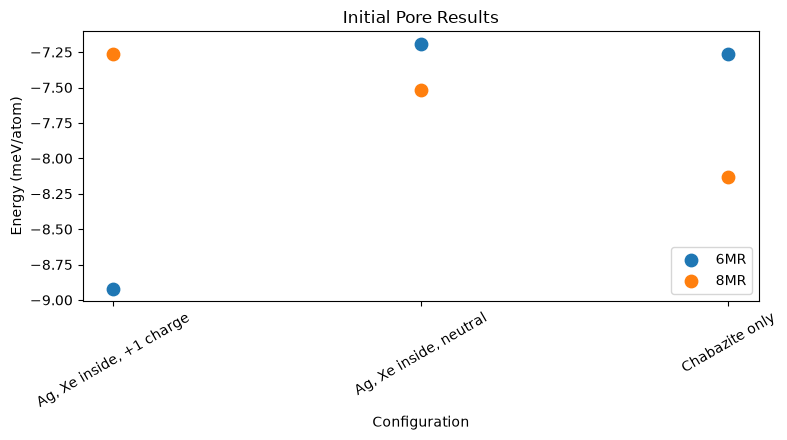

In [7]:
fig, ax = plt.subplots(figsize=(8,4.5))

for ring in df_pore["ring"].unique():
    sub = df_pore[df_pore["ring"] == ring]
    ax.scatter(sub["configuration"], sub["energy_meV_atom"], label=ring, s=80)

ax.set_ylabel("Energy (meV/atom)")
ax.set_xlabel("Configuration")
ax.set_title("Initial Pore Results")
ax.tick_params(axis="x", rotation=30)
ax.legend()
plt.tight_layout()
plt.show()

### Initial interpretation
- ring environment matters
- Ag charge state changes the energy
- 6MR and 8MR do not show identical trends
- the dataset is still too small for robust statistical conclusions

This motivates generating more configurations with MatterSim / MD / DFT.

### Each row = one adsorption configuration

**Features X**
- ring type
- Ag charge / site
- Xe–Ag geometry
- pore descriptors
- AgNP size / concentration

**Target y**
- \(E_{ads}\)

# 4. Main Data Challenges

### Simulation quality
- DFT calculations must be converged
- k-point / pseudopotential / charge settings must be consistent

### Structure organization
- Ag may migrate during relaxation
- multiple Xe sites can come from the same parent zeolite

### Dataset issues
- current dataset is small
- Ag nanoparticle results are still pending
- categorical variables need encoding
- closely related structures can create **data leakage**

> A grouped train/test split by parent structure is preferable to a completely random split.

### Ag nanoparticle status
- planned sizes: 1, 2, 3 nm
- multiple concentrations
- Lennard-Jones is insufficient
- UF3 MLIP is under development

# 5. Suitable ML Algorithms

Because \(E_{ads}\) is continuous, this is a regression problem.

### Baseline
**Linear Regression**
- simple
- interpretable
- tests whether the relationship is approximately linear

### Main model
**Random Forest Regressor**
- captures nonlinear relationships
- handles feature interactions
- works well for tabular materials descriptors
- provides feature importance

### Comparison
**Gradient Boosting Regressor**

## Hyperparameters to tune

### Random Forest
- `n_estimators`
- `max_depth`
- `min_samples_split`
- `min_samples_leaf`
- `max_features`

### Gradient Boosting
- `n_estimators`
- `learning_rate`
- `max_depth`

In [9]:
rf_param_grid = {
    "n_estimators": [100, 300, 500],
    "max_depth": [None, 5, 10, 20],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", 0.5, 1.0]
}

rf_param_grid

{'n_estimators': [100, 300, 500],
 'max_depth': [None, 5, 10, 20],
 'min_samples_split': [2, 5, 10],
 'min_samples_leaf': [1, 2, 4],
 'max_features': ['sqrt', 0.5, 1.0]}

# 6. Success Criteria

Use three regression metrics:

### MAE
Average absolute error.

### RMSE
Penalizes large prediction errors more strongly.

### \(R^2\)
Measures how much of the target variation is explained by the model.

### A useful model should
1. outperform a simple baseline
2. have low MAE / RMSE relative to the energy spread
3. show stable cross-validation performance
4. correctly rank strong vs weak adsorption configurations
5. identify candidates worth DFT validation

# 7. Still Needs to Be Figured Out

### Immediate questions
1. How well does MatterSim reproduce DFT relative / adsorption energies?
2. Which descriptors should be extracted consistently from relaxed structures?
3. How should multiple adsorption sites from the same parent structure be grouped?
4. Which MLIP is best for Ag nanoparticle MD?
5. How much more data are needed before ML training is trustworthy?

### Immediate next step
Generate more relaxed adsorption configurations with MatterSim, organize them into one table, and validate representative cases against DFT.